<center><h1>Xie_Zihan_HW3</h1></center>
<br>
<br>

Name: Zihan Xie
<br>
Github Username: SherryXiYe
<br>
USC ID: 6376813348

# 0. Environment Setup

Required Python packages are listed in `requirements.txt`.

To install the dependencies, run:

```bash
pip install -r requirements.txt

## 1. Time Series Classification Part 1: Feature Creation/Extraction

### (a) Download Data

Package imports

In [1]:
import os, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_selection import f_classif

np.random.seed(42)   # reproducible bootstrap
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 60)

Get the AReM Data Set

In [2]:
ACTIVITIES = ["bending1", "bending2", "cycling", "lying", "sitting", "standing", "walking"]
COLS = ["avg_rss12", "var_rss12", "avg_rss13", "var_rss13", "avg_rss23", "var_rss23"]

def find_data_dir(root="data"):
    """Return the folder under `root` that contains the 7 activity folders (or None)."""
    for dirpath, dirnames, _ in os.walk(root):
        if all(a in dirnames for a in ACTIVITIES):
            return dirpath
    return None

DATA_DIR = find_data_dir("data")
assert DATA_DIR is not None, "AReM data not found: expected the 7 activity folders under ./data/AReM"
print("Data directory:", DATA_DIR)

def file_no(fname):
    """dataset12.csv -> 12 (used for natural sorting and for the train/test split)."""
    return int(re.search(r"(\d+)", fname).group(1))

for a in ACTIVITIES:
    files = [f for f in os.listdir(os.path.join(DATA_DIR, a)) if f.startswith("dataset")]
    print(f"{a:9s} {len(files):2d} files")

Data directory: data\AReM
bending1   7 files
bending2   6 files
cycling   15 files
lying     15 files
sitting   15 files
standing  15 files
walking   15 files


### (b) Test and Train Data

In [3]:
def load_instance(path):
    """Read one AReM file into a DataFrame (n_timesteps x 6 series)."""
    rows = []
    with open(path, "r", errors="ignore") as f:
        for line in f:
            line = line.strip()
            if not line or line.startswith("#"):
                continue
            parts = [p for p in re.split(r"[,\s]+", line) if p != ""]
            try:
                vals = [float(p) for p in parts]
            except ValueError:            # stray header line
                continue
            if len(vals) == 7:            # time + 6 series
                rows.append(vals[1:])
    return pd.DataFrame(rows, columns=COLS)

# Test set: datasets 1 and 2 in bending1 and bending2, datasets 1, 2 and 3 in the other folders.
# Everything else is training data.
def is_test(activity, idx):
    return idx in ((1, 2) if activity in ("bending1", "bending2") else (1, 2, 3))

instances = []
for a in ACTIVITIES:
    folder = os.path.join(DATA_DIR, a)
    for fname in sorted([f for f in os.listdir(folder) if f.startswith("dataset")], key=file_no):
        i = file_no(fname)
        instances.append(dict(activity=a, idx=i, data=load_instance(os.path.join(folder, fname)),
                              split="test" if is_test(a, i) else "train"))

meta = pd.DataFrame([{k: v for k, v in d.items() if k != "data"} for d in instances])
meta["n_timesteps"] = [len(d["data"]) for d in instances]
meta.index = np.arange(1, len(meta) + 1)
meta.index.name = "Instance"

print("Total instances:", len(meta))
print("Series lengths :", meta["n_timesteps"].value_counts().to_dict())
print("Instances whose length is not 480:")
print(meta[meta["n_timesteps"] != 480])
print()
print(meta.groupby(["activity", "split"]).size().unstack(fill_value=0))
print("\nTrain instances:", (meta["split"] == "train").sum(), "| Test instances:", (meta["split"] == "test").sum())
print("Missing values:", sum(d["data"].isna().sum().sum() for d in instances))

Total instances: 88
Series lengths : {480: 87, 479: 1}
Instances whose length is not 480:
         activity  idx  split  n_timesteps
Instance                                  
51        sitting    8  train          479

split     test  train
activity             
bending1     2      5
bending2     2      4
cycling      3     12
lying        3     12
sitting      3     12
standing     3     12
walking      3     12

Train instances: 69 | Test instances: 19
Missing values: 0


The data set contains 88 instances; 69 are used for training and 19 for testing. All series have 480 time steps except one instance (`sitting/dataset8`) with 479, which has no effect on the summary statistics used below. 

### (c) Feature Extraction

#### i. Research

Time-domain features that are commonly used for time series classification, for a series $x_1,\dots,x_n$:

| Category | Features |
|---|---|
| Location / level | minimum, maximum, mean, median, mode, first and third quartiles (Q1, Q3), other percentiles |
| Spread | standard deviation, variance, range (max − min), inter-quartile range (Q3 − Q1), mean absolute deviation, coefficient of variation |
| Shape of the distribution | skewness, kurtosis |
| Energy / magnitude | root mean square (RMS), signal energy $\sum x_i^2$, sum of absolute values (signal magnitude area), peak-to-peak amplitude |
| Dynamics / shape in time | zero-crossing and mean-crossing rate, number of peaks, mean and standard deviation of the first differences, slope of a linear trend, location of the maximum/minimum |
| Dependence / complexity | autocorrelation at different lags, approximate / sample entropy |

Many of these are also implemented in feature libraries such as `tsfresh`, `tsfel` and `catch22`. In this assignment we use: **minimum, maximum, mean, median, standard deviation, first quartile and third quartile**.

#### ii. Extraction

In [4]:
FEATURE_TYPES = ["min", "max", "mean", "median", "std", "1st_quart", "3rd_quart"]

def extract_features(arr):
    """
    arr: ndarray of shape (n_timesteps, n_series).
    Returns a dict {min1, max1, mean1, median1, std1, 1st_quart1, 3rd_quart1, min2, ...}.
    """
    out = {}
    for j in range(arr.shape[1]):
        x = arr[:, j]
        k = j + 1
        out[f"min{k}"]       = np.min(x)
        out[f"max{k}"]       = np.max(x)
        out[f"mean{k}"]      = np.mean(x)
        out[f"median{k}"]    = np.median(x)
        out[f"std{k}"]       = np.std(x, ddof=1)       # sample standard deviation
        out[f"1st_quart{k}"] = np.percentile(x, 25)
        out[f"3rd_quart{k}"] = np.percentile(x, 75)
    return out

features = pd.DataFrame([extract_features(d["data"].values) for d in instances], index=meta.index)
FEATURE_COLS = list(features.columns)
dataset = pd.concat([meta[["activity", "split"]], features], axis=1)

print("Feature matrix:", features.shape)   # 88 instances x (7 features x 6 series)
dataset.head()

Feature matrix: (88, 42)


,activity,split,min1,max1,mean1,median1,std1,1st_quart1,3rd_quart1,min2,max2,mean2,median2,std2,1st_quart2,3rd_quart2,min3,max3,mean3,median3,std3,1st_quart3,3rd_quart3,min4,max4,mean4,median4,std4,1st_quart4,3rd_quart4,min5,max5,mean5,median5,std5,1st_quart5,3rd_quart5,min6,max6,mean6,median6,std6,1st_quart6,3rd_quart6
Instance,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
1,bending1,test,37.25,45.00,40.624792,40.50,1.476967,39.25,42.00,0.0,1.30,0.358604,0.43,0.322605,0.00,0.50,4.0,29.50,19.040937,19.250,4.462952,16.00,23.2500,0.0,7.23,0.832542,0.50,0.965659,0.00,1.120,27.25,38.25,34.311292,35.0,2.188449,33.0000,36.00,0.0,1.92,0.570583,0.43,0.582915,0.0,1.30
2,bending1,test,38.00,45.67,42.812812,42.50,1.435550,42.00,43.67,0.0,1.22,0.372437,0.47,0.289158,0.00,0.50,2.0,29.50,20.096979,21.000,3.893737,19.00,22.2500,0.0,5.76,0.876438,0.50,1.047259,0.00,1.145,27.67,38.50,33.024583,33.0,1.995255,32.0000,34.50,0.0,3.11,0.571083,0.43,0.601010,0.0,1.30
3,bending1,train,35.00,47.40,43.954500,44.33,1.558835,43.00,45.00,0.0,1.70,0.426250,0.47,0.338690,0.00,0.50,6.5,29.75,22.122354,23.000,3.030943,19.75,24.0000,0.0,4.44,0.497312,0.43,0.550657,0.00,0.830,29.00,38.50,35.588458,36.0,1.999604,35.3625,36.50,0.0,1.79,0.493292,0.43,0.513506,0.0,0.94
4,bending1,train,33.00,47.75,42.179812,43.50,3.670666,39.15,45.00,0.0,3.00,0.696042,0.50,0.630860,0.00,1.12,8.5,30.00,22.183625,23.000,3.810469,20.50,24.3725,0.0,5.15,0.989917,0.83,0.953730,0.43,1.300,20.00,38.67,33.493917,35.0,3.849448,30.4575,36.33,0.0,2.18,0.613521,0.50,0.524317,0.0,1.00
5,bending1,train,33.00,45.75,41.678063,41.75,2.243490,41.33,42.75,0.0,2.83,0.535979,0.50,0.405469,0.43,0.71,3.0,28.25,19.006563,19.125,4.087107,16.50,22.0625,0.0,6.42,0.841875,0.50,0.928801,0.43,1.120,23.67,37.50,29.857083,30.0,2.411026,28.4575,31.25,0.0,1.79,0.383292,0.43,0.389164,0.0,0.50


#### iii. Standard Deviation

In [5]:
# Standard deviation of every feature over the 88 instances
X = features.values
n = X.shape[0]
std_hat = X.std(axis=0, ddof=1)

# 90% percentile bootstrap confidence interval: resample the 88 instances with replacement B times,
# recompute the standard deviation of every feature, and take the 5th and 95th percentiles.
B = 2000
boot_idx = np.random.randint(0, n, size=(B, n))
boot_std = np.array([X[idx].std(axis=0, ddof=1) for idx in boot_idx])
ci_low, ci_high = np.percentile(boot_std, [5, 95], axis=0)

std_table = pd.DataFrame({"std_estimate": std_hat,
                          "boot_mean": boot_std.mean(axis=0),
                          "CI90_lower": ci_low,
                          "CI90_upper": ci_high}, index=FEATURE_COLS)
print(std_table.round(3).to_string())

            std_estimate  boot_mean  CI90_lower  CI90_upper
min1               9.570      9.461       8.253      10.726
max1               4.394      4.308       3.343       5.290
mean1              5.336      5.286       4.681       5.900
median1            5.440      5.390       4.779       6.022
std1               1.772      1.757       1.572       1.946
1st_quart1         6.154      6.105       5.549       6.672
3rd_quart1         5.139      5.078       4.283       5.855
min2               0.000      0.000       0.000       0.000
max2               5.063      5.036       4.631       5.410
mean2              1.574      1.567       1.403       1.706
median2            1.412      1.405       1.247       1.545
std2               0.884      0.880       0.808       0.942
1st_quart2         0.946      0.942       0.836       1.038
3rd_quart2         2.125      2.116       1.909       2.298
min3               2.956      2.941       2.762       3.112
max3               4.875      4.822     

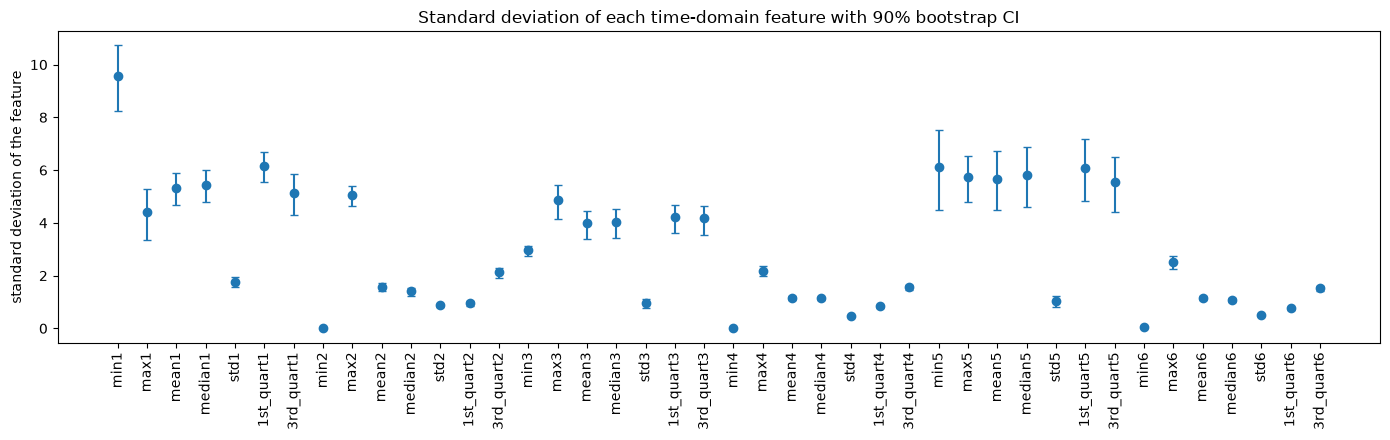

In [6]:
fig, ax = plt.subplots(figsize=(14, 4.5))
xs = np.arange(len(FEATURE_COLS))
ax.errorbar(xs, std_hat, yerr=[std_hat - ci_low, ci_high - std_hat], fmt="o", capsize=3)
ax.set_xticks(xs)
ax.set_xticklabels(FEATURE_COLS, rotation=90)
ax.set_ylabel("standard deviation of the feature")
ax.set_title("Standard deviation of each time-domain feature with 90% bootstrap CI")
plt.tight_layout()
plt.show()

The bootstrap intervals are fairly narrow for most features, so 88 instances give a reasonably stable estimate of the spread of each feature. The exceptions are `min2` and `min4` (the minimum of the two variance series `var_rss12` and `var_rss13`): they equal 0 in every instance, so their estimated standard deviation is 0 and the interval degenerates to [0, 0].

#### iv. Select Features

In [7]:
# (1) Redundancy: average absolute correlation between feature types (averaged over the 6 series)
red = pd.DataFrame(0.0, index=FEATURE_TYPES, columns=FEATURE_TYPES)
for k in range(1, 7):
    sub = features[[f"{t}{k}" for t in FEATURE_TYPES]]
    sub.columns = FEATURE_TYPES
    red += sub.corr().abs() / 6
print("Average absolute correlation between feature types (min is NaN because min2 and min4 are constant):")
print(red.round(2))

# (2) Class separation: ANOVA F-score of every feature for the 7 activities, on the training data only
train_mask = (dataset["split"] == "train").values
F, _ = f_classif(features.loc[train_mask], dataset.loc[train_mask, "activity"])
Fs = pd.Series(F, index=FEATURE_COLS)
f_by_type = pd.DataFrame({t: [Fs[f"{t}{k}"] for k in range(1, 7)] for t in FEATURE_TYPES},
                         index=[f"series{k}" for k in range(1, 7)])
print("\nANOVA F-score (higher = better separation of the activities):")
print(f_by_type.round(1))
print("\nMean F-score per feature type:")
print(f_by_type.mean().round(1))

Average absolute correlation between feature types (min is NaN because min2 and min4 are constant):
           min   max  mean  median   std  1st_quart  3rd_quart
min        NaN   NaN   NaN     NaN   NaN        NaN        NaN
max        NaN  1.00  0.79    0.76  0.60       0.73       0.81
mean       NaN  0.79  1.00    0.99  0.63       0.98       0.98
median     NaN  0.76  0.99    1.00  0.63       0.98       0.97
std        NaN  0.60  0.63    0.63  1.00       0.63       0.59
1st_quart  NaN  0.73  0.98    0.98  0.63       1.00       0.95
3rd_quart  NaN  0.81  0.98    0.97  0.59       0.95       1.00

ANOVA F-score (higher = better separation of the activities):
          min   max   mean  median    std  1st_quart  3rd_quart
series1  11.0   1.5   15.9    17.5    9.1       21.4        8.5
series2   NaN  47.7  900.2   477.0  360.9      265.5      807.0
series3  22.7  31.7   26.4    19.4   15.2       21.2       28.1
series4   NaN  29.3  651.8   800.8  128.6      244.8      561.9
series5  24.1

c:\Users\Lenovo\.conda\envs\database\Lib\site-packages\sklearn\feature_selection\_univariate_selection.py:110: UserWarning: Features [ 7 21] are constant.
  warnings.warn("Features %s are constant." % constant_features_idx, UserWarning)
c:\Users\Lenovo\.conda\envs\database\Lib\site-packages\sklearn\feature_selection\_univariate_selection.py:111: RuntimeWarning: invalid value encountered in divide
  f = msb / msw


**Selected features: `mean`, `std` (standard deviation) and `max`.**

- **`min` is not suitable.** `min2` and `min4` are constant (0) in all instances, so they carry no information, and on the other series `min` has the lowest average F-score (about 15).
- **`mean` separates the activities best** (average F-score about 368, and 580–900 on series 2, 4 and 6), so it is selected.
- **`median`, `1st_quart` and `3rd_quart` are redundant with `mean`**: their average absolute correlation with the mean is about 0.97–0.99, so they add almost no new information.
- **`std` is only moderately correlated with `mean` (about 0.63)** and still separates the classes well (average F-score about 109). It describes how much the signal fluctuates, which complements the level described by the mean.
- **`max` is moderately correlated with `mean` (about 0.79)** and adds information about the upper range of the signal, without the degeneracy of `min`.

Hence the three selected time-domain features are `mean`, `std` and `max`: they keep good class separation while being far less redundant than the other candidates. The mean describes the average signal level, the standard deviation captures signal variability, and the maximum reflects peak signal values. Together, they summarize complementary aspects of the sensor measurements that help distinguish different activities.

In [8]:
SELECTED_TYPES = ["mean", "std", "max"]
SELECTED_FEATURES = [f"{t}{k}" for k in (1, 2, 6) for t in SELECTED_TYPES]
print(SELECTED_FEATURES)
dataset[["activity", "split"] + SELECTED_FEATURES].head()

['mean1', 'std1', 'max1', 'mean2', 'std2', 'max2', 'mean6', 'std6', 'max6']


,activity,split,mean1,std1,max1,mean2,std2,max2,mean6,std6,max6
Instance,,,,,,,,,,,
1,bending1,test,40.624792,1.476967,45.00,0.358604,0.322605,1.30,0.570583,0.582915,1.92
2,bending1,test,42.812812,1.435550,45.67,0.372437,0.289158,1.22,0.571083,0.601010,3.11
3,bending1,train,43.954500,1.558835,47.40,0.426250,0.338690,1.70,0.493292,0.513506,1.79
4,bending1,train,42.179812,3.670666,47.75,0.696042,0.630860,3.00,0.613521,0.524317,2.18
5,bending1,train,41.678063,2.243490,45.75,0.535979,0.405469,2.83,0.383292,0.389164,1.79


## 2. ISLR 3.7.4

We collect $n=100$ observations of one predictor $X$ and a quantitative response $Y$, and fit a linear regression $Y=\beta_0+\beta_1X+\epsilon$ and a cubic regression $Y=\beta_0+\beta_1X+\beta_2X^2+\beta_3X^3+\epsilon$ (the linear model is the special case $\beta_2=\beta_3=0$ of the cubic model).

### (a) Linear Train

**The cubic regression is expected to have a lower training RSS** (the linear regression has the higher one), even though the true relationship is linear. The cubic model contains the linear model as a special case, so its least-squares fit can never have a larger RSS; the extra terms $X^2$ and $X^3$ let it fit some of the random noise $\epsilon$ in the training data.

### (b) Linear Test

**The linear regression has the lower test RSS** (the cubic regression has the higher one). The linear model has the correct form, so it has essentially no bias and lower variance. The cubic model estimates two unnecessary parameters and overfits the training noise, which increases its variance and its expected RSS on new data.

### (c) Not Linear Train

**The cubic regression has the lower training RSS.** As in (a), the more flexible nested model never has a higher training RSS, and here the cubic terms can additionally capture part of the true non-linear structure.

### (d) Not Linear Testing

**There is not enough information to tell**; it depends on how far the true relationship is from linear.

- If the true relationship is closer to linear, the bias of the linear model is small and the extra variance of the cubic model dominates, so the **linear** regression has the lower test RSS.
- If the true relationship is closer to cubic (or is much more non-linear than linear), the bias of the linear model dominates and the **cubic** regression has the lower test RSS.

## 3. ISLR 3.7.3 - Extra Practice 

## 3. ISLR 3.7.5 - Extra Practice 